# Bedroom Humidity Forecasting


***

#### Notebook Overview


#### Data Overview

***
#### Key Findings

#### Next Steps

## Imports

In [1]:
# preprocessing
from utils import DataCleanPipleLine

# funcs
from utils.useful_funcs import season_decomp

# viz
import matplotlib.pyplot as plt
import seaborn as sns
from utils import plotting as plot

# files
import os

# time series eda

# ACF / PACF (numeric values and plots)
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Decomposition
from statsmodels.tsa.seasonal import seasonal_decompose, STL

# Stationarity tests
from statsmodels.tsa.stattools import adfuller, kpss

# models

# ARIMA / SARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX   # SARIMA = SARIMAX without exog

# Gradient boosting
from xgboost import XGBRegressor

# Random forest and linear regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

## Data Import

In [2]:

# import data
file_location = os.getenv("F_LOC")

# run data load
cleaning_pipeline = DataCleanPipleLine
pipe_obj = cleaning_pipeline.DataImportAndCleaningPipeline(file_location)

# run pipeline
window_df = pipe_obj.RunPipeline(impute_missing_data=True)



****************************************************************************************************
DF Shape: (256497, 4)
****************************************************************************************************
****************************************************************************************************
                   DateTime  Temperature (oC)   Pressure   Humidity
256496  2026-11-16 12:38:20             14.65  988.64952  66.418948
256497  2026-11-16 12:39:20             14.67  988.69850  66.311520
256498  2026-11-16 12:40:21             14.63  988.58560  66.426760
256499  2026-11-16 12:41:21             14.63  988.68445  66.493164
256500  2026-11-16 12:42:21             14.66  988.66440  66.365232
256501  2026-11-16 12:43:21             14.67  988.67190  66.266600
256502  2026-11-16 12:44:21             14.67  988.61880  66.177732
256503  2026-11-16 12:45:21             14.66  988.69110  66.065430
256504  2026-11-16 12:46:21             14.63  988.63868  66.17

## Time Series Forecasting: Pre-Modelling Analysis

* Distributions
* Trend and seasonality
* Stationarity
* Autocorrelation

In [3]:
window_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 333594 entries, 2026-03-29 20:54:00+00:00 to 2026-11-16 12:47:00+00:00
Freq: min
Data columns (total 12 columns):
 #   Column               Non-Null Count   Dtype              
---  ------               --------------   -----              
 0   Temperature (oC)     333594 non-null  float64            
 1   Pressure             333594 non-null  float64            
 2   Humidity             333594 non-null  float64            
 3   DateTime             256479 non-null  datetime64[us, UTC]
 4   Sensor_Status        333594 non-null  str                
 5   Date                 333594 non-null  datetime64[s]      
 6   YearMonth            333594 non-null  period[M]          
 7   EndOfWeek            333594 non-null  datetime64[s]      
 8   Time                 333594 non-null  object             
 9   Time_Numeric         333594 non-null  timedelta64[us]    
 10  DailyAvgTemperature  333594 non-null  float64            
 11  DailyAvgHumidity    

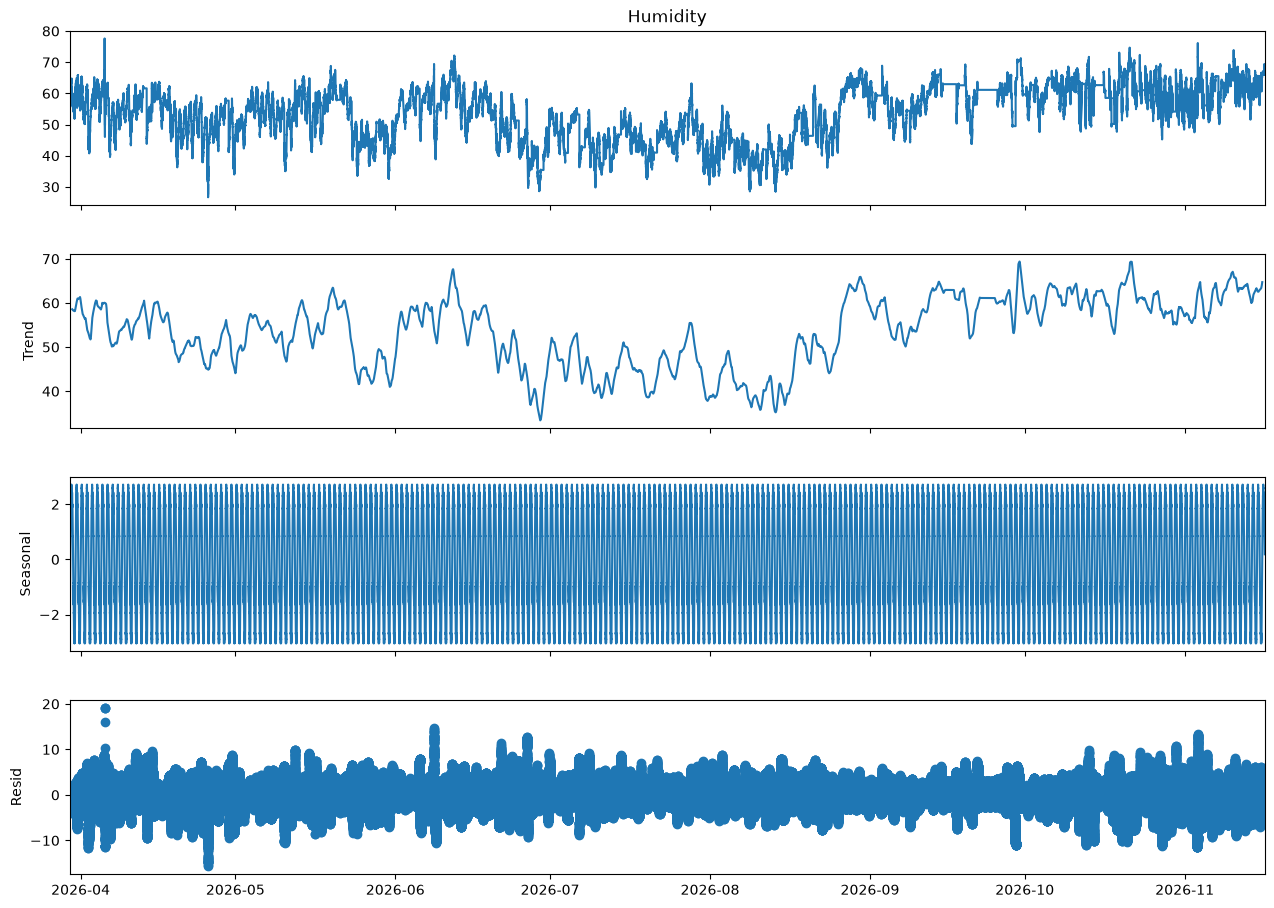

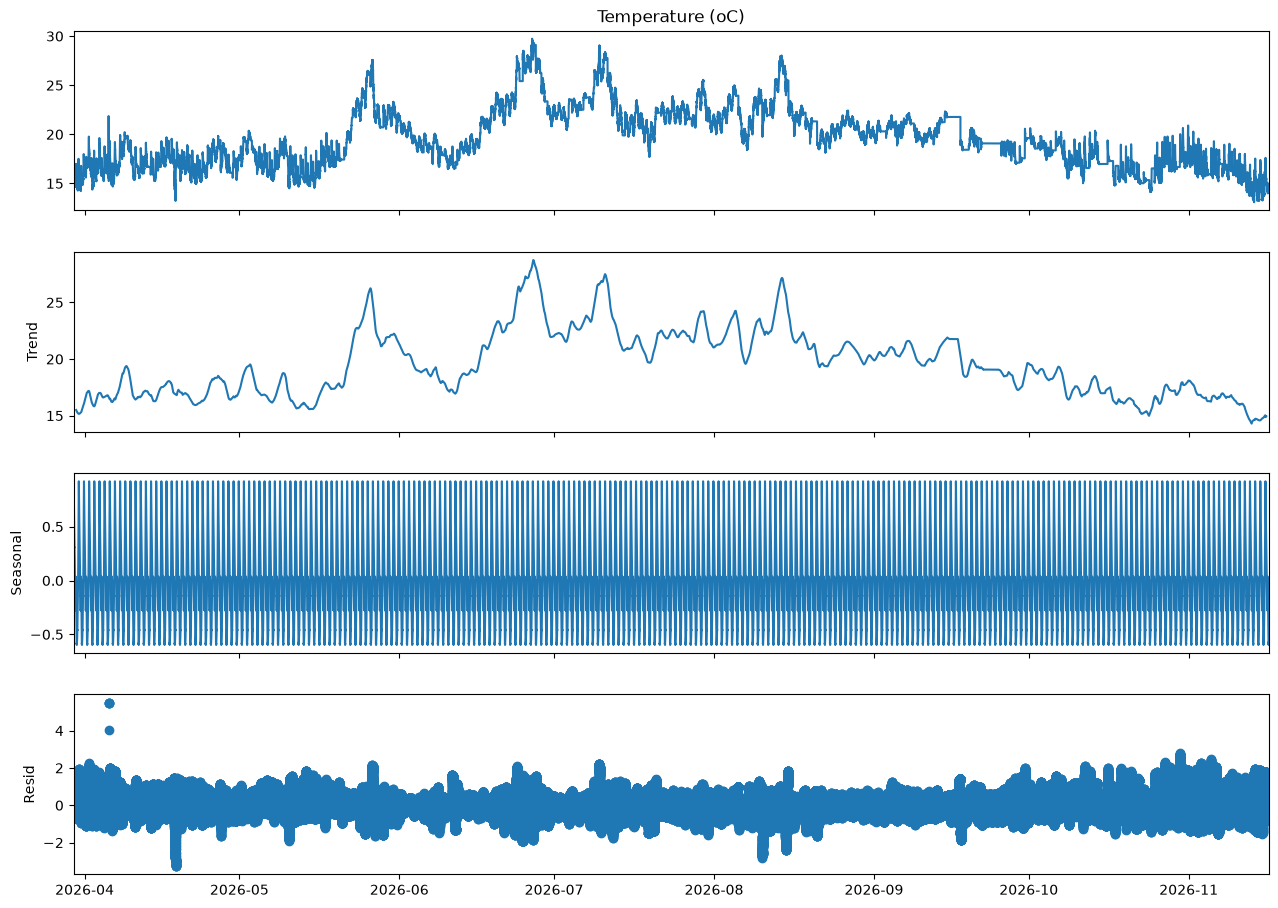

In [4]:
# run a season decomposition on humidity and temp - minutely data

hum_temp_df = window_df[['Humidity','Temperature (oC)']]
model= 'additive'

for feature in hum_temp_df.columns:
    # run seasonal decomp
    result = seasonal_decompose(hum_temp_df[feature], model=model, period=1440)

    #plot results
    fig = result.plot();
    fig.set_size_inches(14, 10)
    plt.show();


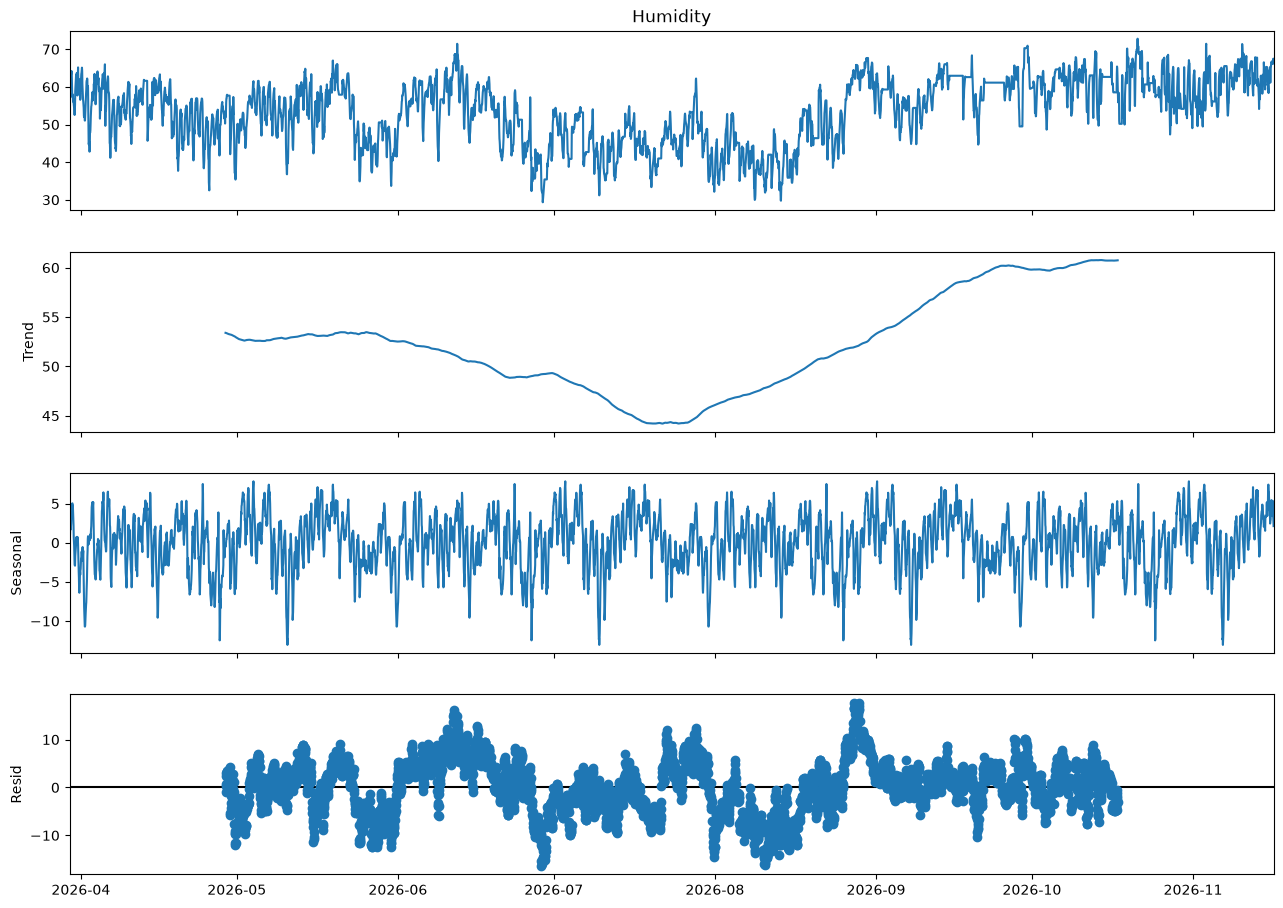

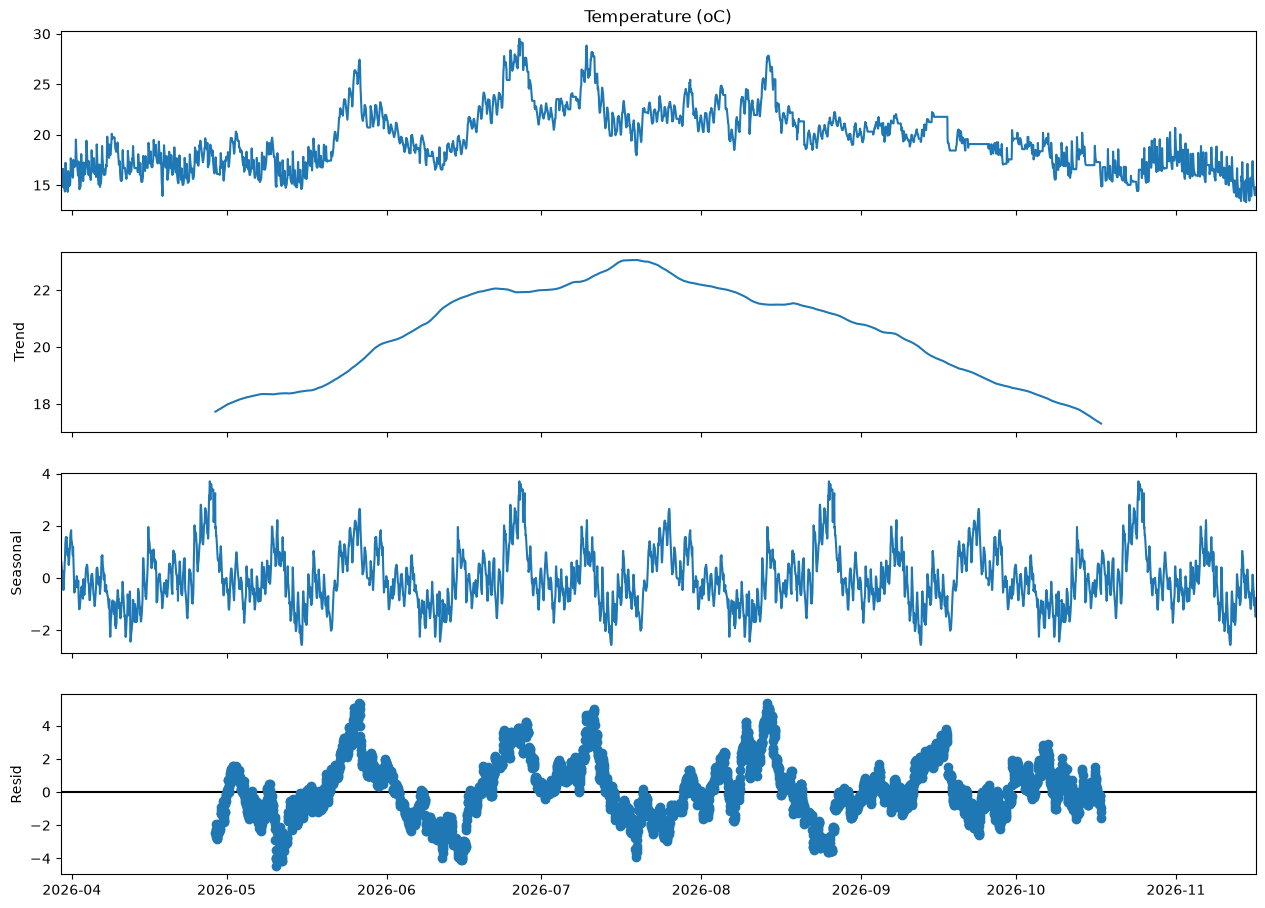

In [5]:
season_decomp(df=window_df,resample_size="1h")

### Modelling

* Naive and seasonal naive baselines
* Classical statistical model (ARIMA / SARIMA)
* Machine learning models (lag and rolling features)
* Model comparison and evaluation

### Results